# Transfer Learning 2 - ResNet50
Same data, same training steps as the MobileNetV2 notebook, but with ResNet50.
At the end it loads `mobilenetv2_best.pt` and compares the two models.

## Setup

In [14]:
import os, copy, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms as T
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED, IMG_SIZE, BATCH = 42, 224, 32
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"   # mac gpu
else:
    device = "cpu"
print("device:", device)

os.makedirs("reports", exist_ok=True)

device: mps


## Data

In [15]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

train_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.8, 1.25)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(0.3, 0.3, 0.2, 0.02),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

train_ds = datasets.ImageFolder("train", transform=train_tf)
val_ds = datasets.ImageFolder("val", transform=eval_tf)
test_ds = datasets.ImageFolder("test", transform=eval_tf)
classes = train_ds.classes
n_classes = len(classes)
paths = [p for p, _ in test_ds.samples]

print(classes)
print("train", len(train_ds), "val", len(val_ds), "test", len(test_ds))

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, generator=g)
val_loader = DataLoader(val_ds, batch_size=BATCH)
test_loader = DataLoader(test_ds, batch_size=BATCH)

['apple', 'banana', 'carrot', 'cucumber', 'lemon', 'orange', 'potato', 'tomato']
train 402 val 86 test 87


## Model and training functions

In [16]:
def build_resnet():
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    for p in model.parameters():
        p.requires_grad = False                            # freeze everything pretrained
    model.fc = nn.Linear(model.fc.in_features, n_classes)  # new last layer for our 8 classes
    return model.to(device)

criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total, correct, loss_sum = 0, 0, 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.set_grad_enabled(training):
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        loss_sum += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
        total += len(y)
    return loss_sum / total, correct / total

def fit(model, optimizer, epochs, stage, history, patience=3, verbose=True):
    best_acc, best_state, bad_epochs = -1, None, 0
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader)
        history.append(dict(stage=stage, train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss, val_acc=va_acc))
        if verbose:
            print(f"{stage} ep {ep:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f}")
        if va_acc > best_acc:
            best_acc, best_state, bad_epochs = va_acc, copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:   # early stopping
                if verbose:
                    print(f"{stage}: no val improvement for {patience} epochs, stopping")
                break
    model.load_state_dict(best_state)   # keep the epoch with the best val acc
    return best_acc

def train_resnet(lr_head=1e-3, lr_ft=1e-4, unfreeze=1, epochs_head=15, epochs_ft=25, patience=3, verbose=True):
    torch.manual_seed(SEED)
    model = build_resnet()
    history = []

    # stage 1: only the new last layer learns
    opt = torch.optim.Adam(model.fc.parameters(), lr=lr_head)
    fit(model, opt, epochs_head, "head", history, patience, verbose)

    # stage 2: unfreeze the last block(s). resnet has 4 big blocks: layer1..layer4
    blocks = [model.layer1, model.layer2, model.layer3, model.layer4]
    for b in blocks[-unfreeze:]:
        for p in b.parameters():
            p.requires_grad = True
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr_ft)
    best_val = fit(model, opt, epochs_ft, "finetune", history, patience, verbose)

    return model, pd.DataFrame(history), best_val

## Train (default settings)

In [17]:
start = time.time()
model, hist, best_val = train_resnet()
train_minutes = (time.time() - start) / 60
print("best val acc:", round(best_val, 3), "| training time:", round(train_minutes, 1), "min")

head ep  1 | train loss 1.886 acc 0.303 | val loss 1.560 acc 0.756
head ep  2 | train loss 1.329 acc 0.764 | val loss 1.135 acc 0.884
head ep  3 | train loss 0.981 acc 0.878 | val loss 0.891 acc 0.919
head ep  4 | train loss 0.761 acc 0.898 | val loss 0.737 acc 0.907
head ep  5 | train loss 0.603 acc 0.945 | val loss 0.622 acc 0.907
head ep  6 | train loss 0.522 acc 0.938 | val loss 0.550 acc 0.907
head: no val improvement for 3 epochs, stopping
finetune ep  1 | train loss 0.587 acc 0.893 | val loss 0.378 acc 0.872
finetune ep  2 | train loss 0.226 acc 0.968 | val loss 0.252 acc 0.907
finetune ep  3 | train loss 0.129 acc 0.968 | val loss 0.211 acc 0.942
finetune ep  4 | train loss 0.087 acc 0.990 | val loss 0.199 acc 0.907
finetune ep  5 | train loss 0.061 acc 0.983 | val loss 0.199 acc 0.930
finetune ep  6 | train loss 0.042 acc 0.993 | val loss 0.195 acc 0.942
finetune: no val improvement for 3 epochs, stopping
best val acc: 0.942 | training time: 1.0 min


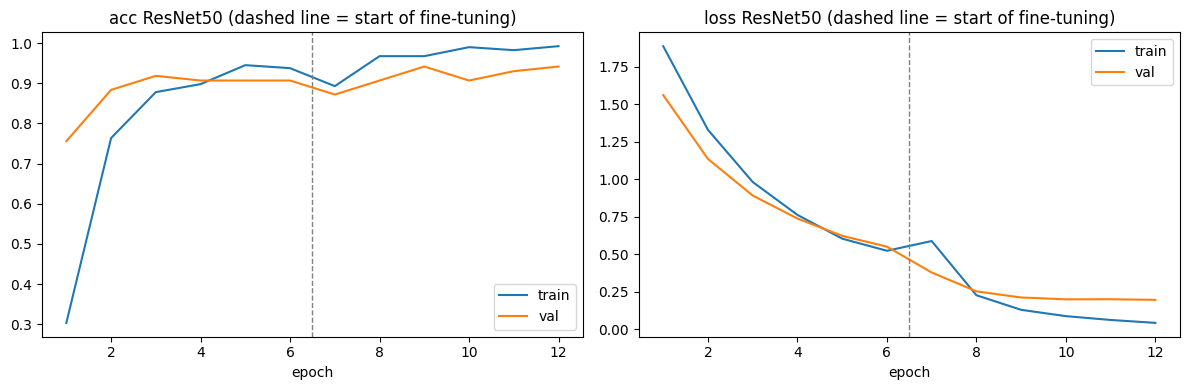

In [18]:
def plot_history(hist, title, fname):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    x = range(1, len(hist) + 1)
    switch = (hist.stage == "head").sum() + 0.5
    for a, m in zip(ax, ["acc", "loss"]):
        a.plot(x, hist["train_" + m], label="train")
        a.plot(x, hist["val_" + m], label="val")
        a.axvline(switch, color="gray", ls="--", lw=1)
        a.set(title=f"{m} {title}", xlabel="epoch")
        a.legend()
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()

plot_history(hist, "ResNet50 (dashed line = start of fine-tuning)", "reports/resnet_history.png")

## Tuning
Same idea as before: try a few settings, keep the best **val** accuracy.
`unfreeze=1` = only layer4 learns in stage 2, `unfreeze=2` = layer3 and layer4.
ResNet50 is bigger, so this is slower than the MobileNet tuning.

In [19]:
results = [dict(lr_ft=1e-4, unfreeze=1, best_val_acc=round(best_val, 3))]   # the default run
best = dict(val=best_val, model=model, hist=hist, lr_ft=1e-4, unfreeze=1)

for lr_ft, unfreeze in [(1e-4, 2), (3e-4, 1), (3e-4, 2)]:
    m, h, v = train_resnet(lr_ft=lr_ft, unfreeze=unfreeze, verbose=False)
    results.append(dict(lr_ft=lr_ft, unfreeze=unfreeze, best_val_acc=round(v, 3)))
    print(f"lr_ft={lr_ft} unfreeze={unfreeze} -> val acc {v:.3f}")
    if v > best["val"]:
        best = dict(val=v, model=m, hist=h, lr_ft=lr_ft, unfreeze=unfreeze)

print(pd.DataFrame(results).sort_values("best_val_acc", ascending=False).to_string(index=False))
print("using:", best["lr_ft"], best["unfreeze"], "val acc", round(best["val"], 3))

model = best["model"]
torch.save(model.state_dict(), "resnet50_best.pt")

lr_ft=0.0001 unfreeze=2 -> val acc 0.930
lr_ft=0.0003 unfreeze=1 -> val acc 0.988
lr_ft=0.0003 unfreeze=2 -> val acc 0.953
 lr_ft  unfreeze  best_val_acc
0.0003         1         0.988
0.0003         2         0.953
0.0001         1         0.942
0.0001         2         0.930
using: 0.0003 1 val acc 0.988


## Test set

test accuracy: 0.943
              precision    recall  f1-score   support

       apple      0.941     1.000     0.970        16
      banana      0.909     1.000     0.952        10
      carrot      1.000     1.000     1.000        11
    cucumber      1.000     0.889     0.941         9
       lemon      0.769     1.000     0.870        10
      orange      1.000     0.667     0.800         9
      potato      1.000     0.917     0.957        12
      tomato      1.000     1.000     1.000        10

    accuracy                          0.943        87
   macro avg      0.952     0.934     0.936        87
weighted avg      0.952     0.943     0.941        87



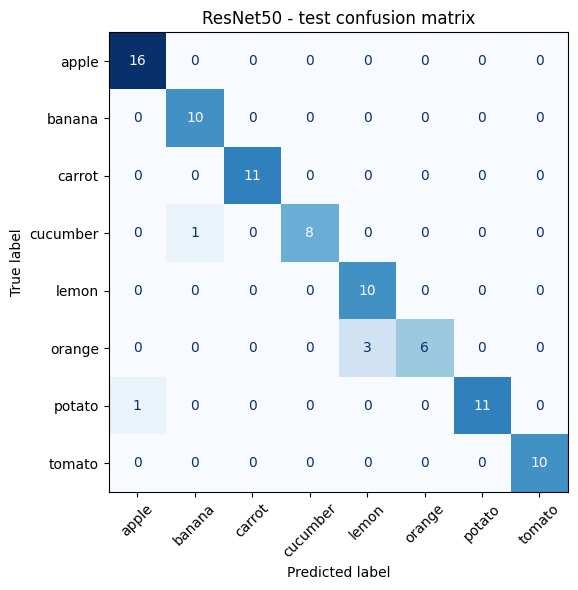

In [20]:
def predict(model, loader):
    model.eval()
    preds, probs, labels = [], [], []
    with torch.no_grad():
        for x, y in loader:
            p = F.softmax(model(x.to(device)), dim=1).cpu()
            probs.append(p); preds.append(p.argmax(1)); labels.append(y)
    return torch.cat(labels).numpy(), torch.cat(preds).numpy(), torch.cat(probs).numpy()

y_true, y_pred, y_prob = predict(model, test_loader)
print("test accuracy:", round((y_true == y_pred).mean(), 3))
print(classification_report(y_true, y_pred, labels=range(n_classes), target_names=classes, digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=range(n_classes))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("ResNet50 - test confusion matrix")
plt.tight_layout()
plt.savefig("reports/resnet_confusion_matrix.png", dpi=150)
plt.show()

## Error analysis

    true predicted  count
  orange     lemon      3
cucumber    banana      1
  potato     apple      1
5 wrong out of 87


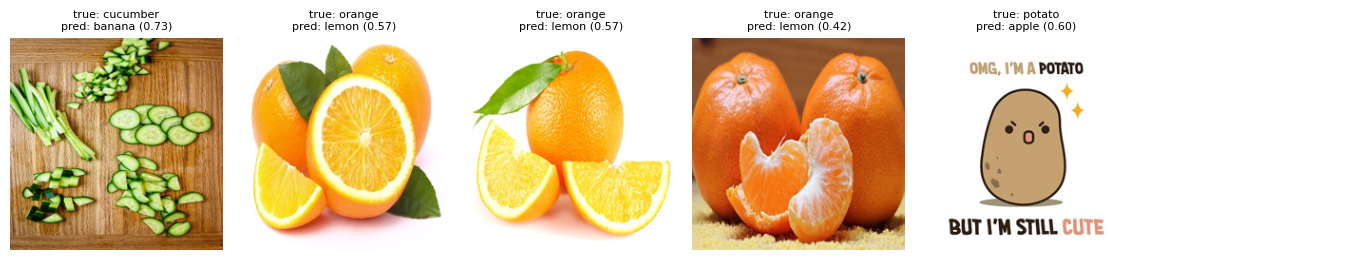

In [21]:
pairs = [(classes[i], classes[j], cm[i, j]) for i in range(n_classes) for j in range(n_classes) if i != j and cm[i, j] > 0]
print(pd.DataFrame(pairs, columns=["true", "predicted", "count"]).sort_values("count", ascending=False).to_string(index=False))

wrong = np.where(y_true != y_pred)[0]
print(len(wrong), "wrong out of", len(y_true))

if len(wrong):
    cols = 6
    rows = int(np.ceil(len(wrong[:24]) / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(cols * 2.3, rows * 2.6), squeeze=False)
    for a in ax.ravel():
        a.axis("off")
    for a, i in zip(ax.ravel(), wrong[:24]):
        a.imshow(Image.open(paths[i]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
        a.set_title(f"true: {classes[y_true[i]]}\npred: {classes[y_pred[i]]} ({y_prob[i].max():.2f})", fontsize=8)
    plt.tight_layout()
    plt.savefig("reports/resnet_errors.png", dpi=150)
    plt.show()

## Grad-CAM

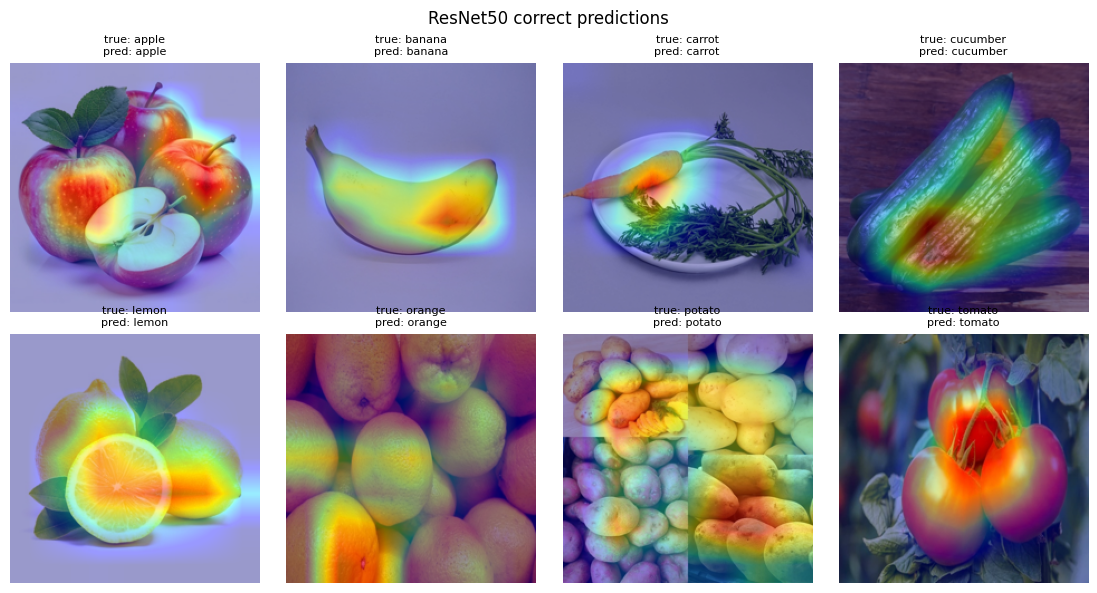

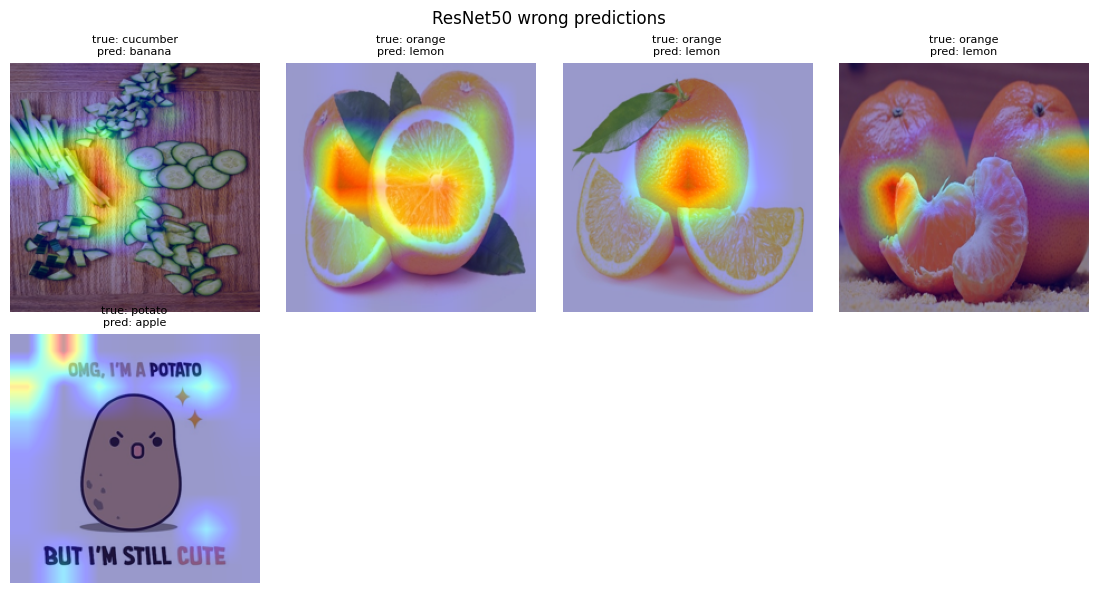

In [22]:
def grad_cam(model, layer, x, class_idx=None):
    saved = {}

    def fwd_hook(m, inp, out):
        saved["act"] = out
        out.register_hook(lambda grad: saved.__setitem__("grad", grad))

    h = layer.register_forward_hook(fwd_hook)
    model.eval()
    x = x.unsqueeze(0).to(device).requires_grad_(True)
    out = model(x)
    if class_idx is None:
        class_idx = out.argmax(1).item()
    model.zero_grad()
    out[0, class_idx].backward()
    h.remove()

    weights = saved["grad"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * saved["act"]).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
    cam = cam.squeeze().detach().cpu().numpy()
    return cam / (cam.max() + 1e-8), class_idx

def show_cams(model, layer, idx_list, title, fname):
    cols = 4
    rows = int(np.ceil(len(idx_list) / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(cols * 2.8, rows * 3), squeeze=False)
    for a in ax.ravel():
        a.axis("off")
    for a, i in zip(ax.ravel(), idx_list):
        x, y = test_ds[i]
        cam, pred = grad_cam(model, layer, x)
        a.imshow(Image.open(paths[i]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
        a.imshow(cam, cmap="jet", alpha=0.4)
        a.set_title(f"true: {classes[y]}\npred: {classes[pred]}", fontsize=8)
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()

layer = model.layer4[-1]   # last conv block in resnet50
right = [np.where((y_true == c) & (y_pred == c))[0] for c in range(n_classes)]
show_cams(model, layer, [r[0] for r in right if len(r)], "ResNet50 correct predictions", "reports/resnet_gradcam_correct.png")
if len(wrong):
    show_cams(model, layer, list(wrong[:8]), "ResNet50 wrong predictions", "reports/resnet_gradcam_wrong.png")

## Compare with MobileNetV2
Loads `mobilenetv2_best.pt` (saved by the MobileNet notebook) and runs both models on the same val and test sets.

In [23]:
mobile = models.mobilenet_v2(weights=None)
mobile.classifier[1] = nn.Linear(mobile.last_channel, n_classes)
mobile.load_state_dict(torch.load("mobilenetv2_best.pt", map_location=device))
mobile = mobile.to(device)

def ms_per_image(model):
    model.eval()
    with torch.no_grad():
        for x, _ in test_loader:          # warm up
            model(x.to(device)); break
        start = time.time()
        for x, _ in test_loader:
            model(x.to(device))
    return (time.time() - start) / len(test_ds) * 1000

def n_params(model):
    return sum(p.numel() for p in model.parameters()) / 1e6

m_true, m_pred, m_prob = predict(mobile, test_loader)
_, m_val = run_epoch(mobile, val_loader)

compare = pd.DataFrame([
    dict(model="MobileNetV2", val_acc=round(m_val, 3), test_acc=round((m_true == m_pred).mean(), 3),
         test_wrong=int((m_true != m_pred).sum()), params_millions=round(n_params(mobile), 1),
         file_mb=round(os.path.getsize("mobilenetv2_best.pt") / 1e6, 1), ms_per_image=round(ms_per_image(mobile), 1)),
    dict(model="ResNet50", val_acc=round(best["val"], 3), test_acc=round((y_true == y_pred).mean(), 3),
         test_wrong=int((y_true != y_pred).sum()), params_millions=round(n_params(model), 1),
         file_mb=round(os.path.getsize("resnet50_best.pt") / 1e6, 1), ms_per_image=round(ms_per_image(model), 1)),
])
compare.to_csv("reports/model_comparison.csv", index=False)
compare

,model,val_acc,test_acc,test_wrong,params_millions,file_mb,ms_per_image
0,MobileNetV2,0.977,0.977,2,2.2,9.2,2.7
1,ResNet50,0.988,0.943,5,23.5,94.4,4.3


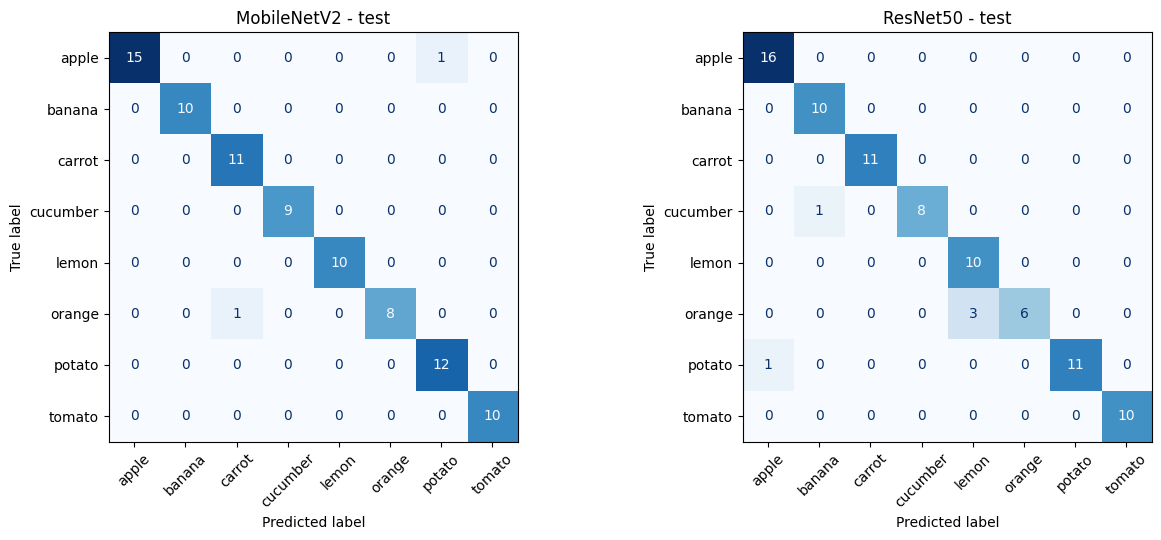

wrong by both: 0
wrong by MobileNetV2 only: 2
wrong by ResNet50 only: 5


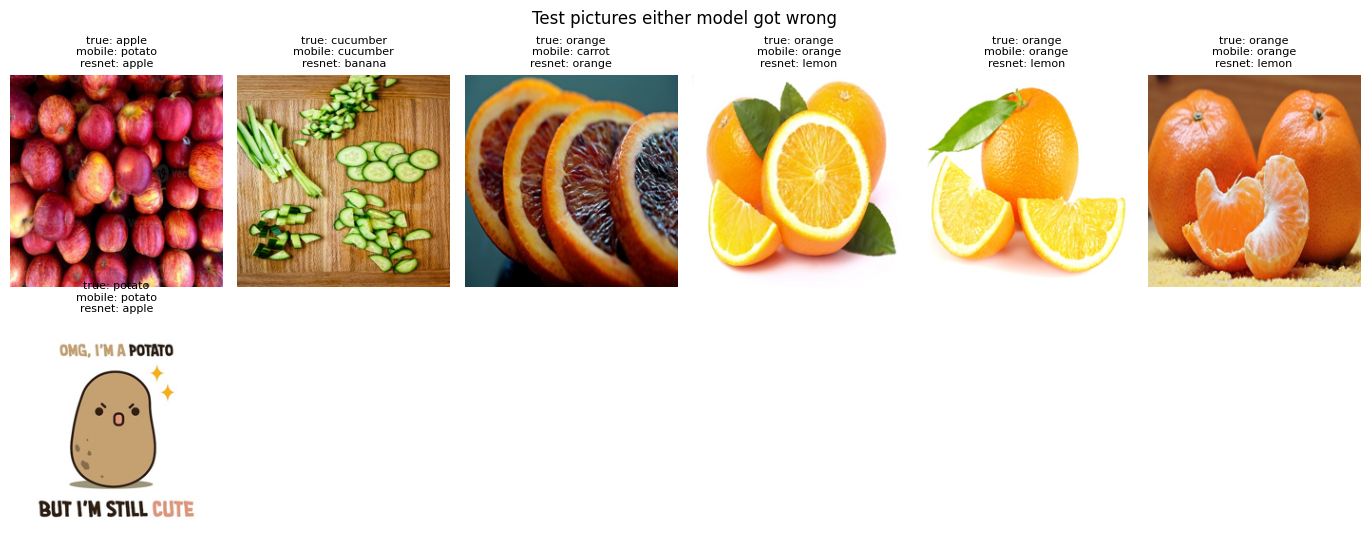

In [24]:
# confusion matrices side by side
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, (name, pred) in zip(ax, [("MobileNetV2", m_pred), ("ResNet50", y_pred)]):
    c = confusion_matrix(y_true, pred, labels=range(n_classes))
    ConfusionMatrixDisplay(c, display_labels=classes).plot(ax=a, cmap="Blues", xticks_rotation=45, colorbar=False)
    a.set_title(f"{name} - test")
plt.tight_layout()
plt.savefig("reports/confusion_matrix_comparison.png", dpi=150)
plt.show()

# did they get the same pictures wrong?
m_wrong = set(np.where(m_true != m_pred)[0])
r_wrong = set(np.where(y_true != y_pred)[0])
print("wrong by both:", len(m_wrong & r_wrong))
print("wrong by MobileNetV2 only:", len(m_wrong - r_wrong))
print("wrong by ResNet50 only:", len(r_wrong - m_wrong))

both = sorted(m_wrong | r_wrong)
if both:
    cols = 6
    rows = int(np.ceil(len(both[:24]) / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(cols * 2.3, rows * 2.8), squeeze=False)
    for a in ax.ravel():
        a.axis("off")
    for a, i in zip(ax.ravel(), both[:24]):
        a.imshow(Image.open(paths[i]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
        a.set_title(f"true: {classes[y_true[i]]}\nmobile: {classes[m_pred[i]]}\nresnet: {classes[y_pred[i]]}", fontsize=8)
    plt.suptitle("Test pictures either model got wrong")
    plt.tight_layout()
    plt.savefig("reports/errors_comparison.png", dpi=150)
    plt.show()

## Extra runs (different seeds)
Same idea as in the MobileNet notebook: 3 more runs with the same settings, only the seed changes.
Does **not** change `resnet50_best.pt` or anything above.

Run this after the MobileNet notebook's extra runs, and after the compare cells above
(it reads `reports/model_comparison.csv`).
If the notebook was restarted: run **Setup**, **Data** and **Model and training functions** first.
Don't re-run Train or Tuning.

In [25]:
try:
    lr_ft, unfreeze = best["lr_ft"], best["unfreeze"]
except NameError:
    lr_ft, unfreeze = 1e-4, 1   # notebook was restarted: put what the tuning cell printed after "using:"
print("settings: lr_ft", lr_ft, "unfreeze", unfreeze)

main = pd.read_csv("reports/model_comparison.csv").set_index("model").loc["ResNet50"]

def test_acc(m):
    m.eval()
    correct = 0
    with torch.no_grad():
        for x, y in test_loader:
            correct += (m(x.to(device)).argmax(1).cpu() == y).sum().item()
    return correct / len(test_ds)

runs = [dict(model="ResNet50", seed="42 (main)", val_acc=main.val_acc, test_acc=main.test_acc)]
for s in [1, 7, 123]:
    SEED = s            # train_resnet uses SEED inside
    g.manual_seed(s)    # shuffle order
    m, h, v = train_resnet(lr_ft=lr_ft, unfreeze=unfreeze, verbose=False)
    t = test_acc(m)
    runs.append(dict(model="ResNet50", seed=s, val_acc=round(v, 3), test_acc=round(t, 3)))
    print(f"seed {s}: val {v:.3f} test {t:.3f}")
SEED = 42

runs = pd.DataFrame(runs)
runs.to_csv("reports/resnet_seed_runs.csv", index=False)
print(runs.to_string(index=False))
print(f"test acc mean {runs.test_acc.mean():.3f}, min {runs.test_acc.min():.3f}, max {runs.test_acc.max():.3f}")

settings: lr_ft 0.0003 unfreeze 1
seed 1: val 0.977 test 0.954
seed 7: val 0.953 test 0.920
seed 123: val 0.977 test 0.989
   model      seed  val_acc  test_acc
ResNet50 42 (main)    0.988     0.943
ResNet50         1    0.977     0.954
ResNet50         7    0.953     0.920
ResNet50       123    0.977     0.989
test acc mean 0.951, min 0.920, max 0.989


## Compare over all runs

      model      seed  val_acc  test_acc
MobileNetV2 42 (main)    0.977     0.977
MobileNetV2         1    0.977     0.989
MobileNetV2         7    0.977     0.977
MobileNetV2       123    0.977     0.977
   ResNet50 42 (main)    0.988     0.943
   ResNet50         1    0.977     0.954
   ResNet50         7    0.953     0.920
   ResNet50       123    0.977     0.989


,runs,val_mean,test_mean,test_min,test_max,test_std
model,,,,,,
MobileNetV2,4,0.977,0.980,0.977,0.989,0.006
ResNet50,4,0.974,0.952,0.920,0.989,0.029


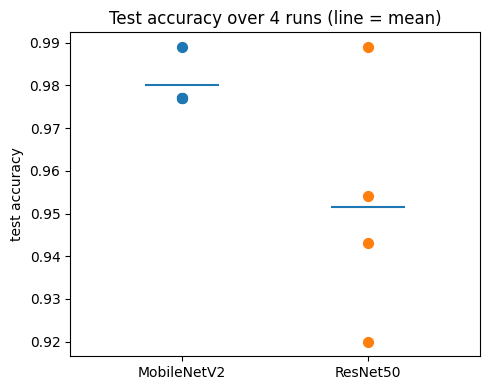

In [26]:
allruns = pd.concat([pd.read_csv("reports/mobilenet_seed_runs.csv"), pd.read_csv("reports/resnet_seed_runs.csv")])
summ = allruns.groupby("model").agg(
    runs=("test_acc", "size"),
    val_mean=("val_acc", "mean"),
    test_mean=("test_acc", "mean"),
    test_min=("test_acc", "min"),
    test_max=("test_acc", "max"),
    test_std=("test_acc", "std"),
).round(3)
summ.to_csv("reports/seed_comparison.csv")
print(allruns.to_string(index=False))
display(summ)

names = sorted(allruns.model.unique())
plt.figure(figsize=(5, 4))
for i, name in enumerate(names):
    d = allruns[allruns.model == name]
    plt.scatter([i] * len(d), d.test_acc, s=50)
    plt.hlines(d.test_acc.mean(), i - 0.2, i + 0.2)
plt.xticks(range(len(names)), names)
plt.xlim(-0.6, len(names) - 0.4)
plt.ylabel("test accuracy")
plt.title("Test accuracy over 4 runs (line = mean)")
plt.tight_layout()
plt.savefig("reports/seed_comparison.png", dpi=150)
plt.show()